# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Finn McLachlan, Thomas Sinclair, Tarra Sai Sridhar, Bagus Kurniawan**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd      # tables (DataFrames): loading, reshaping and grouping the data
import numpy as np       # fast maths on arrays: logs, percentiles, random numbers

# Plotting libraries
import matplotlib.pyplot as plt   # basic plotting
import seaborn as sns             # statistical plots on top of matplotlib (heatmaps, violins)

# sklearn modules
import sklearn

from sklearn.cluster import KMeans                     # k-means clustering
from sklearn.cluster import AgglomerativeClustering    # hierarchical clustering (sklearn version)
from scipy.cluster import hierarchy                    # Ward linkage and the dendrogram plot
from sklearn.pipeline import Pipeline                  # (not used yet)
from sklearn.compose import ColumnTransformer          # (not used yet)
from sklearn.impute import SimpleImputer               # (not used yet)
from sklearn.preprocessing import StandardScaler       # rescales each feature to mean 0, standard deviation 1
from sklearn.metrics import (
    silhouette_score, silhouette_samples, adjusted_rand_score   # cluster quality and agreement scores
)
from sklearn.decomposition import PCA                  # (not used yet)

# Same clean style and colour-blind friendly colours for every figure
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Load data
# Each level file has one row per monitoring series and one column per day
df_avg = pd.read_csv("avg_river_levels.csv")        # daily average level (m)
df_min = pd.read_csv("min_river_levels.csv")        # daily minimum level (m)
df_max = pd.read_csv("max_river_levels.csv")        # daily maximum level (m)
df_locs = pd.read_csv("monitoring_locations.csv")   # latitude and longitude of each series (for the cluster map)

# Show the first rows to see the layout: 3 ID columns, then one column per date
df_avg.head()

,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

We have been asked by the Scottish Government to offer insights into river water levels using the daily data of minimum, average and maximum water levels for each of the 392 monitoring series between October 2014 and October 2026. 
The following work  will be answers two questions: 
- Group monitoring stations together based on similarities in their water level behaviour.
- Create a classifier that can predict if a monitoring station will flood based on the previous seven days of water levels.

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

## Loading and combining the data

The data come as three wide files (daily minimum, average and maximum level), each with one row per monitoring series and one column per day. A fourth file gives the latitude and longitude of each station. 

We first checked that all three files list the same 392 series in the same order, so a row means the same series in every file.

In [ ]:
# The three files should hold identical stations and dates, so they can be merged row by row.
# First check all three tables have the same number of rows and columns (stops with an error if not)
assert df_min.shape == df_avg.shape == df_max.shape
# then check if the series are listed in exactly the same order in every file
assert (df_min["Observation_ID"] == df_avg["Observation_ID"]).all() and (df_max["Observation_ID"] == df_avg["Observation_ID"]).all()
# How much data we have (the first 3 columns are County, Station_Name and Observation_ID, the rest are days)
print(f"{df_avg.shape[0]} monitoring series, {df_avg.shape[1] - 3} days "
      f"({df_avg.columns[3]} to {df_avg.columns[-1]})")

392 monitoring series, 4379 days (05/10/2014 to 08/10/2026)


Our next step was to reshape ("melt") each file so there is one row per series per day, and join the three into one larger table, `df_main`. This long layout makes it easy to work by station (for the clustering) or by date (for the classification), which we will move onto later. Rows where all three levels are missing are dropped, and the dates are converted from text into real dates.

In [4]:
# Reshape each wide file (one column per day) into a long table (one row per series per day).
# The long layout is much easier to group by station (clustering) or by date (classification).

# Average level: keep the three ID columns and turn every date column into rows
df_avg_long = df_avg.melt(
    id_vars=["County","Station_Name","Observation_ID"],   # columns kept as they are
    var_name="Date",                                       # the old column names (dates) go into "Date"
    value_name="Avg_Level"                                 # the readings go into "Avg_Level"
)

# Same for the minimum level
df_min_long = df_min.melt(
    id_vars=["County","Station_Name","Observation_ID"],
    var_name="Date",
    value_name="Min_Level"
)
# Same for the maximum level
df_max_long = df_max.melt(
    id_vars=["County","Station_Name","Observation_ID"],
    var_name="Date",
    value_name="Max_Level"
)

# Join the three long tables so each row holds the min, max and average for one series on one day
df_main = (
    df_min_long
    .merge(df_max_long, on=["Observation_ID","County","Station_Name","Date"], how="inner")   # add the max level
    .merge(df_avg_long, on=["Observation_ID","County","Station_Name","Date"], how="inner")   # add the average level
)

# Drop days where all three readings are missing (e.g. before a station started recording)
df_main = df_main.dropna(subset=["Min_Level", "Max_Level", "Avg_Level"], how="all")

# Turn the date text (dd/mm/yyyy) into real dates; anything unreadable becomes missing (NaT)
df_main["Date"] = pd.to_datetime(df_main["Date"], dayfirst=True, errors="coerce")
# Count the rows whose date could not be read
n_bad = df_main["Date"].isna().sum()
# If there are any, report them and remove them
if n_bad:
    print(f"Dropping {n_bad} rows with unparseable dates")
    df_main = df_main.dropna(subset=["Date"]).copy()

In [5]:
# Column names, types and number of rows of the combined table (about 1.19 million rows)
df_main.info()

print("\nRaw level distribution (before cleaning):")

# Summary of the raw readings: the extreme min/max values (e.g. 999999.999) are clearly error codes
df_main[["Avg_Level", "Min_Level", "Max_Level"]].describe().T.round(3)

<class 'pandas.DataFrame'>
Index: 1190691 entries, 122 to 1716567
Data columns (total 7 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1190691 non-null  str           
 1   Station_Name    1190691 non-null  str           
 2   Observation_ID  1190691 non-null  str           
 3   Date            1190691 non-null  datetime64[us]
 4   Min_Level       1190691 non-null  float64       
 5   Max_Level       1190691 non-null  float64       
 6   Avg_Level       1190691 non-null  float64       
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 72.7 MB

Raw level distribution (before cleaning):


,count,mean,std,min,25%,50%,75%,max
Avg_Level,1190691.0,3.884,1185.799,-190475.436,0.292,0.477,0.763,999999.999
Min_Level,1190691.0,-22.948,5019.457,-999999.999,0.250,0.430,0.670,999999.999
Max_Level,1190691.0,40.347,6282.618,-29.638,0.324,0.540,0.935,999999.999


 We noticed that the original data had values that were physically impossible for Scottish rivers (e.g. 999,999.999m, maximum river levels, as well as minimum levels of -190,475m, which were clearly implausable), so must be cleaned before being used to obtain any results.

## Finding the coastal stations

The brief says some sites have a tidal and a non-tidal stations. Coastal gauges measure the sea, which goes up and down with the tides rather than with rain, so they behave nothing like a river and need to be found early. When we initially approached this problem we flagged a station as tidal if the word "tidal" appeared in its ID. That found us 12 of such coastal stations. However after further analysis we noticed each of those 12 had a partner station at the same site. The partner wasn't labelled tidal, but if it moved in step with the tidal station, then it must be measuring the sea too. Going by the name alone would leave these partners mixed in with the conventional rivers.

The function below which we have implemented takes each "tidal-level" station, finds the other station at the same site and measures how closely the two move together (the correlation), ignoring the error codes. Each station of each pair are then flagged as a coastal station.

In [ ]:
def find_coastal_series(df_wide):
    """
    Identify coastal (sea-level) monitoring series.

    The brief notes that some stations have a tidal and a non-tidal observation.
    IDs containing "tidal-level" are tidal; their partner series at the same site
    is also checked, by correlation, to see whether it measures sea level too.

    Parameters
    ----------
    df_wide : DataFrame with an Observation_ID column and one column per day.

    Returns
    -------
    coastal_ids : set of Observation_IDs treated as coastal.
    pairs : DataFrame of each tidal series, its partner and their correlation.
    """
    # Use the series ID as the row label and keep only the day columns (skip County and Station_Name)
    levels = df_wide.set_index("Observation_ID").iloc[:, 2:]
    # Hide error codes (anything beyond +-100 m) so they don't distort the correlation
    levels = levels.where(levels.abs() < 100)

    rows = []
    # Go through every series whose ID contains "tidal-level"
    for tid in [o for o in levels.index if "tidal-level" in o]:
        # Site name = middle part of the ID (county__site__obsN), without the "-tidal-level" ending
        site = tid.split("__")[1].replace("-tidal-level", "")
        # The partner is the other series recorded at exactly that site
        partner = [o for o in levels.index if o.split("__")[1] == site][0]
        # Store the pair and how closely their daily levels move together (1 = perfectly in step)
        rows.append({"site": site, "tidal_series": tid, "partner": partner,
                     "correlation": levels.loc[tid].corr(levels.loc[partner])})
    # One row per tidal series and its partner
    pairs = pd.DataFrame(rows)

    # Both members of every pair count as coastal
    coastal_ids = set(pairs["tidal_series"]) | set(pairs["partner"])
    return coastal_ids, pairs


# Run the check on the wide average-level file
coastal_ids, tidal_pairs = find_coastal_series(df_avg)

# Flag each series: 1 = coastal (tidal or its sea-level partner), 0 = river
obs_lookup = df_main[["Observation_ID"]].drop_duplicates()                      # one row per series
obs_lookup["is_tidal"] = obs_lookup["Observation_ID"].isin(coastal_ids).astype(int)   # 1 if coastal, else 0
# Copy the flag onto every daily row (any older is_tidal column is dropped first so it isn't duplicated)
df_main = df_main.drop(columns="is_tidal", errors="ignore").merge(obs_lookup, on="Observation_ID", how="left")

print(f"{len(coastal_ids)} coastal series flagged")
# Each tidal site and how strongly it moves with its partner
tidal_pairs[["site", "correlation"]].round(3)

24 coastal series flagged


,site,correlation
0,portrush-argyll-and-bute,0.995
1,tobermory-argyll-and-bute,0.991
2,millport-ayrshire-and-arran,0.979
3,wick-caithness,0.967
4,aberdeen-city-of-aberdeen,0.991
5,leith-city-of-edinburgh,0.996
6,ullapool-ross-and-cromarty,0.999
7,lerwick-shetland,0.996
8,kinlochbervie-sutherland,0.990
9,bangor-wigtown,0.978


As we expected all the 12 "tidal-level" stations move almost exactly in step with their partner station at the same site, with correlations between 0.97 and 0.999. For example, the two Leith series rise and fall together on every tide. So there are 24 series measuring the sea rather than a river, and all 24 are flagged as coastal (`is_tidal = 1`). We keep them in the clustering, where they are a useful check on whether the clusters are real, but leave them out of the flood classification.

## Cleaning impossible readings

Continuing on from the implausable values, we recognised them as errors codes which we would remove before any modelling. Initially we did this by removed every reading above +20 m or below −20 m, a limit chosen from a histogram of all readings together, as well as scottish river level websites. The old code is kept, commented out, at the top of the next two cells. This was a good estimate, however, we didn't want to estimate. We noticed each gauge measured height above its specific stations zero point, so "normal" is different for every station. To show this, the new code plots the typical (median) level of each series (Figure 1).

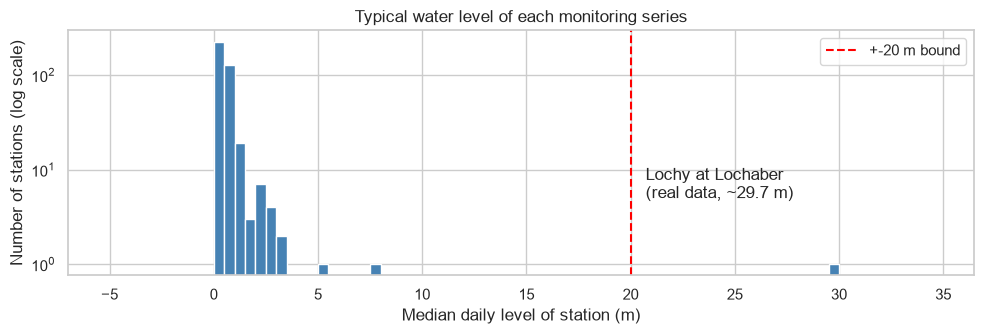

In [21]:
# ==============================================================================
# OLD APPROACH: histogram of all readings with one ±20 m bound
# Problem: every gauge has its own zero point, so one bound for all of Scotland
# either deletes real data (Lochy reads ~29.7 m every day) or keeps errors.
# Kept for reference only. It is commented out and does not run.
# ==============================================================================
# Clearly description states theres problems within the data
# Plot to explore possible bounds. Right now we are using a bound of 20 metres, but this is arbitrary. We can see from the histogram that there are some extreme values that are not realistic for Scottish rivers, 
# and we want to filter those out.

# vals = df_main[["Avg_Level", "Min_Level", "Max_Level"]].to_numpy().ravel()
# vals = vals[np.isfinite(vals)]

# fig, ax = plt.subplots(figsize=(10, 4.5))

# # Plot standard histogram, but limit the x-range to -25 to 25
# # We use 50 bins, which gives a bin width of 1 metre (very intuitive)
# ax.hist(vals, bins=50, range=(-25, 25), 
#         histtype="stepfilled", edgecolor="white", linewidth=0.5,
#         color="steelblue", log=True)

# # Add the bounds
# ax.axvline(-20, ls="--", color="red", lw=1.5, label="Bound = ±20 m")
# ax.axvline( 20, ls="--", color="red", lw=1.5)

# ax.set(
#     xlabel="Level (m)",
#     ylabel="Number of readings (log scale)",
#     title="Distribution of level readings (zoomed to +-25 m)"
# )
# ax.grid(True, which="both", alpha=0.3)
# ax.legend(loc="upper right")

# plt.tight_layout()
# plt.show()

# #NOTE: The histogram shows the distribution of river level readings, with the bounds indicated by red dashed lines. This bound was used to filter out unrealistic values, such as 999999, -99, and 99, 
# # which are not representative of actual river levels in Scotland. The histogram is plotted on a logarithmic scale to better visualize the distribution of readings across the range of -25 to 25 meters.
# # Look at .describe() to see why this was needed.


# ==============================================================================
# NEW APPROACH: typical (median) level of each station (Figure 1)
# ==============================================================================
# Typical (median) level of each station. Levels are measured from each gauge's own zero point,
# so normal levels differ a lot between stations, and one national bound can't separate errors from real data.
station_median = df_main.groupby("Observation_ID")["Avg_Level"].median()

# Histogram of the 392 typical levels (log scale on the y-axis so single stations are still visible)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(station_median, bins=np.arange(-5, 35, 0.5), color="steelblue", edgecolor="white", log=True)
# Red line: where the old ±20 m bound would cut
ax.axvline(20, ls="--", color="red", lw=1.5, label="+-20 m bound")
# Point out Lochy at Lochaber: real data that sits far above 20 m
lochy = station_median["inverness__lochy-lochaber__obs1"]
ax.annotate("Lochy at Lochaber\n(real data, ~29.7 m)", xy=(lochy, 1), xytext=(lochy - 9, 5),
            arrowprops=dict(arrowstyle="->"))
# Labels and title
ax.set(xlabel="Median daily level of station (m)", ylabel="Number of stations (log scale)",
       title="Typical water level of each monitoring series")
ax.legend()
plt.tight_layout(); plt.show()

Figure 1 shows that most stations have a typical level between 0 m and 3 m, but Lochy at Lochaber sits at around 29.7 m every day because its gauge uses a different zero point. A +-20 m limit would remove almost all of its real data.

Thus, instead of using one limit for every scottish water station, we compares each reading with that station's own normal range. For each station we find the middle 50% of its readings (the 25th to 75th percentile, whose width is the IQR). A reading was removed only if it was more than 20 IQRs below or above that middle range. We chose 20 to be generous on purpose: as a real flood pushes a river a few metres above normal, while an error code is thousands of metres off. We also set the IQR to at least 5 cm, so very flat stations don't lose ordinary readings. The daily range (max − min) was worked out after the cleaning process, so that error codes couldn't create impossible daily swings.

In [ ]:
# ==============================================================================
# OLD APPROACH: remove every reading outside +-20 m
# Problem: deletes almost all of Lochy's real data, and keeps error values that
# happen to fall inside ±20 m (daily ranges of up to 38 m were left in).
# Kept for reference only. It is commented out and does not run.
# ==============================================================================
# Implement this bound into data river we consulted links like; (https://en.wikipedia.org/wiki/1993_Perth_flood), https://waterlevels.sepa.org.uk/Station/234235, as well as tidal resources, which meant we
#  could capture the tidal observations within our cleaning of the dataset(https://marine.gov.scot/sma/maps/423)
# BOUND = 20   
# for c in ["Avg_Level", "Min_Level", "Max_Level"]:
#     df_main.loc[df_main[c].abs() > BOUND, c] = np.nan

# #Column for daily range 
# df_main["Range_Level"] = df_main["Max_Level"] - df_main["Min_Level"] #Range calculated after nulling bugged values, otherwise would be unrealistic

# print("\nCleaned level distribution:")
# print(df_main[["Avg_Level", "Min_Level", "Max_Level", "Range_Level"]]
#       .describe().T.round(3))

#NOTE: The cleaned level distribution shows the summary statistics for the average, minimum, maximum, and range of river levels after filtering out unrealistic values. 
# The range is calculated as the difference between the maximum and minimum levels for each observation.


# ==============================================================================
# NEW APPROACH: judge each reading against its own station's normal range
# ==============================================================================
def remove_station_outliers(df, columns, k=20, min_iqr=0.05):
    """
    Set readings to NaN when they lie far outside their own station's typical range.

    A reading is an outlier if it is more than k interquartile ranges (IQRs) below
    the station's 25th percentile or above its 75th percentile. Judging each station
    against itself is needed because gauges measure from different zero points
    (e.g. Lochy at Lochaber normally reads ~29.7 m).

    Parameters
    ----------
    df : long-format DataFrame with an Observation_ID column.
    columns : level columns to clean.
    k : number of IQRs allowed outside the middle 50% of readings.
    min_iqr : smallest IQR used (m), so near-constant stations are not over-trimmed.

    Returns
    -------
    cleaned copy of df, and a dict with the number of readings removed per column.
    """
    df = df.copy()          # work on a copy so the original table isn't changed by accident
    n_removed = {}          # number of readings removed from each column
    for c in columns:
        # Group this column's readings by station
        grp = df.groupby("Observation_ID")[c]
        # Each station's 25th and 75th percentile, copied onto every one of its rows
        q1 = grp.transform(lambda s: s.quantile(0.25))
        q3 = grp.transform(lambda s: s.quantile(0.75))
        # Width of the middle 50% (the IQR), never smaller than min_iqr
        iqr = (q3 - q1).clip(lower=min_iqr)
        # Outlier = more than k IQRs below Q1 or more than k IQRs above Q3
        outlier = (df[c] < q1 - k * iqr) | (df[c] > q3 + k * iqr)
        # Count the outliers, then replace them with NaN (missing)
        n_removed[c] = int(outlier.sum())
        df.loc[outlier, c] = np.nan
    return df, n_removed


# The three level columns to clean
levels = ["Avg_Level", "Min_Level", "Max_Level"]
# k = 20 is generous on purpose: real floods are a few metres, error codes are thousands of metres off
df_main, n_removed = remove_station_outliers(df_main, levels, k=20)
print("Readings set to missing:", n_removed)

# Daily range, computed after cleaning so error codes don't create impossible ranges
df_main["Range_Level"] = df_main["Max_Level"] - df_main["Min_Level"]
# Summary after cleaning: the error codes are gone and the values look realistic
df_main[levels + ["Range_Level"]].describe().T.round(3)

Readings set to missing: {'Avg_Level': 208, 'Min_Level': 213, 'Max_Level': 200}


,count,mean,std,min,25%,50%,75%,max
Avg_Level,1190483.0,0.712,1.504,-6.620,0.292,0.477,0.763,34.243
Min_Level,1190478.0,0.569,1.488,-8.891,0.251,0.430,0.670,34.190
Max_Level,1190491.0,0.872,1.609,-6.620,0.324,0.540,0.934,34.390
Range_Level,1190342.0,0.302,0.748,0.000,0.012,0.044,0.189,11.999


Values were removed which were more than 20 interquartile ranges beyond a stations normal range of values. This meant that approximately 200 values were removed from each station (less than 0.02% of the total dataset) including any error codes (which were hopefully most of the values removed). We then obtained the real world flood peaks. For example historic flooding events have occurred in Scotland (such as the 1993 Perth flood) but these increased levels by just a few metres and are well within the tolerance (SEPA water levels; 1993 Perth flood in References).

## Seasonal behaviour

How strongly a river follows depends heavily on the season that the current station is currently in. This is key to distinguish before building the clustering features. For each station we took the stations average level in each calendar month and subtracted that station's overall mean. Subtracting the station's own mean removes the zero-point problem which meant stations couldnt be compared. Thus we now had that all 392 series could be compared on one plot (Figure 2).

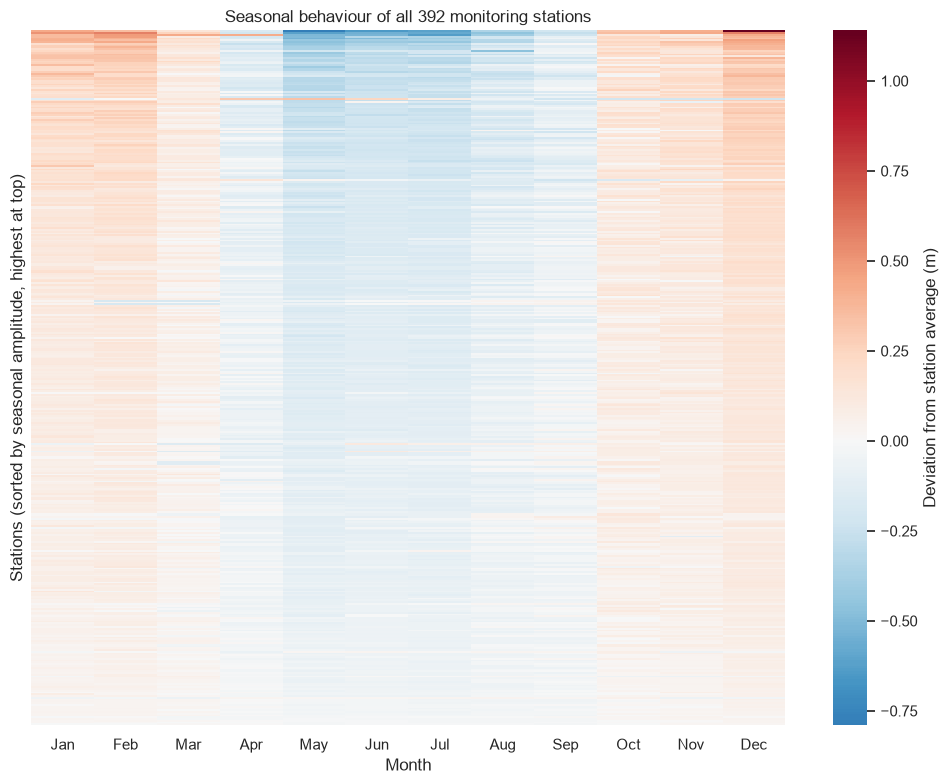

In [24]:
# Average level of every station in each calendar month (rows = stations, columns = months 1-12)
monthly_avg = (
    df_main.assign(month=df_main["Date"].dt.month)    # add a month column (1 = Jan ... 12 = Dec)
    .groupby(["Observation_ID", "month"])["Avg_Level"]
    .mean()                                           # mean level per station per month
    .unstack()                                        # turn the months into columns
)

# Subtract each station's own mean (month average - yearly average), so every row shows
# ups and downs around 0. This removes the zero-point problem and makes stations comparable.
row_norm = monthly_avg.sub(monthly_avg.mean(axis=1), axis=0)

# Seasonal amplitude = wettest month minus driest month (also used later as a clustering feature)
seasonal_amp = monthly_avg.max(axis=1) - monthly_avg.min(axis=1)
# Sort the stations so the most seasonal ones are at the top of the plot
row_norm = row_norm.loc[seasonal_amp.sort_values(ascending=False).index]

# Heatmap of seasonal behaviour of all 392 monitoring stations
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    row_norm,
    cmap="RdBu_r",           # red = above the station's mean, blue = below
    center=0,                # white = exactly the station's mean
    yticklabels=False,       # so we don't see the 392 station names
    xticklabels=["Jan","Feb","Mar","Apr","May","Jun",
                 "Jul","Aug","Sep","Oct","Nov","Dec"],
    cbar_kws={"label": "Deviation from station average (m)"},
    ax=ax,
)
ax.set_xlabel("Month")
ax.set_ylabel("Stations (sorted by seasonal amplitude, highest at top)")
ax.set_title("Seasonal behaviour of all 392 monitoring stations")
plt.tight_layout()
plt.show()

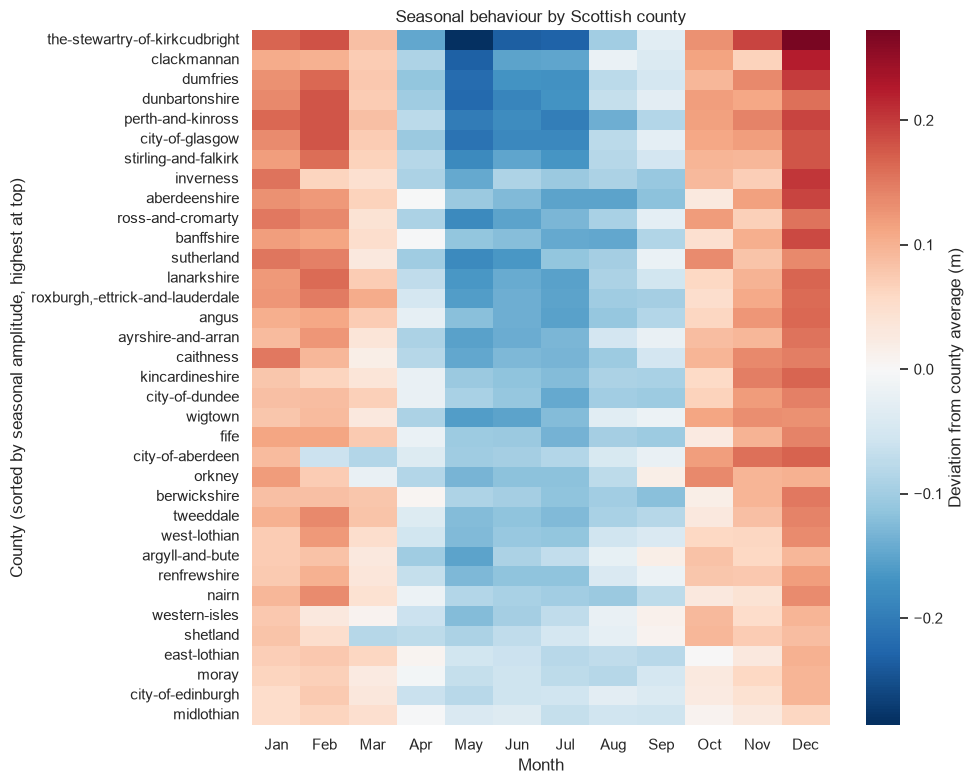

In [25]:
# Average level of every county in each calendar month (rows = counties, columns = months 1-12)
monthly_avg = (
    df_main.assign(month=df_main["Date"].dt.month)    # add a month column (1 = Jan ... 12 = Dec)
    .groupby(["County", "month"])["Avg_Level"]
    .mean()                                           # mean level per county per month
    .unstack()                                        # turn the months into columns
)

# Subtract each county's own mean (month average - yearly average), so every row shows
# ups and downs around 0. This removes the zero-point problem and makes counties comparable.
row_norm = monthly_avg.sub(monthly_avg.mean(axis=1), axis=0)

# Seasonal amplitude = wettest month minus driest month (also used later as a clustering feature)
seasonal_amp = monthly_avg.max(axis=1) - monthly_avg.min(axis=1)
# Sort the counties so the most seasonal ones are at the top of the plot
row_norm = row_norm.loc[seasonal_amp.sort_values(ascending=False).index]

# Heatmap of seasonal behaviour of all Scottish counties
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    row_norm,
    cmap="RdBu_r",           # red = above the county's mean, blue = below
    center=0,                # white = exactly the county's mean
    yticklabels=True,        # show county names (only ~30 rows, so they fit nicely)
    xticklabels=["Jan","Feb","Mar","Apr","May","Jun",
                 "Jul","Aug","Sep","Oct","Nov","Dec"],
    cbar_kws={"label": "Deviation from county average (m)"},
    ax=ax,
)
ax.set_xlabel("Month")
ax.set_ylabel("County (sorted by seasonal amplitude, highest at top)")
ax.set_title("Seasonal behaviour by Scottish county")
plt.tight_layout()
plt.show()

Plots above slightly different we need to choose one

Figure 2 above, shows us the seasonal average levels compared to the total mean, for each station, with every coloured dash represening a station in that specific month (names left out for obvious visual reasons). The stations are ordered in descending order of seasonal amplitude (how much each station differs from 1st mean every month). Almost all the stations have a higher than average level during winter (shown in red, approx. Oct- Feb) and lower levels during summer (shown in blue, approx. May-Aug). However, there is a large variation in how pronounced this seasonal cycle is. Thus we make sure to include this seasonality feature in our clustering.

## Station features for clustering

Our clustering groups stations, not days, thus each of the 392 series has to be summarised by one row of numbers describing how its water level behaves.

We initially went about this using the mean level, standard deviation, mean daily range, seasonal amplitude, number of readings and the tidal flag, and filled any missing values with 0. However, we ran into issues such as the mean level depending on where the gauge's zero point was, not on how the river behaves. This would leave us to believe Lochy is a "huge" river as its zero point is so high. we noticed that the number of readings told us how long a station had been recording, not anything about the rivers daily pattern. We also decided to ommit the tidal flag, as it handed over part of the answer to the clustering model, so we could no longer use the coastal stations to check whether the clusters are real. Finally, the seasonal amplitude came out as all zeros, as the values were indexed by station ID, but the table they were added to had a plain 0, 1, 2,..., index, so nothing matched and every value became missing. `fillna(0)` then quietly turned them all into zeros.

Our final clustering relied on only five features that look at changes, spreads and ratios, so they don't depend on the gauge's zero point. A few stations had extreme skewness and daily swing, so skewness is capped at its 1st and 99th percentiles and daily swing is log-transformed. All five are then standardised so each one counts equally in the distances (Workshops 1 and 3).

In [10]:
# ==============================================================================
# OLD APPROACH: mean level, std, daily range, seasonal amplitude, n_obs, tidal flag
# Problems: the mean level depends on the gauge's zero point, n_obs measures how long
# a gauge has recorded (not river behaviour), the tidal flag gives the answer away,
# and seasonal_amp was all zeros (index mismatch hidden by fillna(0)).
# Kept for reference only. It is commented out and does not run.
# ==============================================================================
# # We have 1.19m rows of daily data. KMeans needs 392 rows (one per station). We are clustering by stations
# # So we group by station and calculate summary statistics

# station = df_main.groupby("Observation_ID").agg(
#     County=("County", "first"), #take the first county name, should be the same for all rows of that same station
#     Station_Name=("Station_Name", "first"),
#     is_tidal=("is_tidal", "first"),
#     avg_level=("Avg_Level", "mean"),           # Typical water level
#     var_level=("Avg_Level", "std"),            # How much it fluctuates
#     daily_range=("Range_Level", "mean"),       # Average daily min-max swing
#     n_obs=("Avg_Level", "count")               # Number of real readings
# ).reset_index()

# #NOTE: in heatmap above we see clear seasonal changes.

# # Add seasonal amplitude (how much the river changes between summer and winter)
# monthly = df_main.groupby(["Observation_ID", df_main["Date"].dt.month])["Avg_Level"].mean().unstack()
# station["seasonal_amp"] = monthly.max(axis=1) - monthly.min(axis=1)

# print(f"We now have {station.shape[0]} rows, one for each station.")

# # We utilise scaling as not all features have same number of observations
# # These are the features that describe a river's behaviour
# features = ["avg_level", "var_level", "daily_range", "seasonal_amp", "n_obs", "is_tidal"]

# # We scale them so they all have a mean of 0 and a standard deviation of 1.
# # This prevents features with large numbers (like n_obs) from overpowering small numbers (like avg_level).
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(station[features].fillna(0))

# print("Data is scaled and ready for KMeans.")

# X_scaled


# ==============================================================================
# NEW APPROACH: five behaviour features that don't depend on the zero point
# ==============================================================================
def make_station_features(df, seasonal_amp, df_locs):
    """
    Summarise each monitoring series into one row of behaviour features for clustering.

    Gauges measure height above their own local zero point, so absolute levels can't be
    compared between stations. Every feature therefore uses spreads, changes or ratios,
    which don't depend on that zero point.

    Parameters
    ----------
    df : cleaned long-format DataFrame (Observation_ID, Date, Avg_Level, Range_Level, ...).
    seasonal_amp : Series indexed by Observation_ID (max minus min monthly mean level).
    df_locs : station locations (Observation_ID, Latitude, Longitude).

    Returns
    -------
    station : DataFrame indexed by Observation_ID with features and descriptive columns.
    spread : Series of each station's 5th–95th percentile range (m).
    """
    # Sort by station and date so "previous row" means "previous day at the same station"
    df = df.sort_values(["Observation_ID", "Date"])
    stn = df["Observation_ID"]           # used to group everything by station

    # Day-to-day change in average level, only between consecutive calendar days
    consecutive = df.groupby(stn)["Date"].diff().dt.days.eq(1)               # True if the previous row is exactly 1 day earlier
    day_change = df.groupby(stn)["Avg_Level"].diff().where(consecutive)      # change from yesterday (missing if there was a gap)

    # Average levels grouped by station
    lvl = df.groupby(stn)["Avg_Level"]
    # Spread = 95th minus 5th percentile: the station's normal range, ignoring the most extreme days
    spread = lvl.quantile(0.95) - lvl.quantile(0.05)

    # One row per station, five behaviour features
    features = pd.DataFrame({
        "log_spread":  np.log(spread),                                    # how much the level rises and falls
        "flashiness":  day_change.abs().groupby(stn).mean() / lvl.std(),  # fast vs slow response
        "skewness":    lvl.skew(),                                        # rare sharp peaks -> right-skewed
        "seasonality": seasonal_amp / spread,                             # share of range due to the seasons
        "daily_swing": df.groupby(stn)["Range_Level"].median() / spread,  # within-day vs overall variation
    })

    # Descriptive information, used only to interpret the clusters (not as clustering features)
    meta = (df.groupby(stn)[["County", "Station_Name", "is_tidal"]].first()        # name, county, coastal flag
            .join(df_locs.set_index("Observation_ID")[["Latitude", "Longitude"]])   # location for the map
            .assign(n_obs=lvl.count()))                                             # number of readings

    # Division by zero gives infinity; turn it into missing so those stations can be found
    features = features.replace([np.inf, -np.inf], np.nan)
    # Report any station with a missing feature, then drop it
    dropped = features.index[features.isna().any(axis=1)]
    print(f"Dropping {len(dropped)} stations with undefined features: {list(dropped)}")
    return features.dropna().join(meta), spread


# Build one row of features per station
station, spread = make_station_features(df_main, seasonal_amp, df_locs)

# Reduce the influence of a few extreme stations before scaling:
# cap skewness at its 1st/99th percentiles, and log-transform the very right-skewed daily swing
station["skewness"] = station["skewness"].clip(*station["skewness"].quantile([0.01, 0.99]))
station["log_daily_swing"] = np.log10(station["daily_swing"] + 0.01)   # +0.01 avoids log(0)

# The five columns the clustering uses
feature_cols = ["log_spread", "flashiness", "skewness", "seasonality", "log_daily_swing"]

# Standardise so every feature contributes equally to the distances (Workshop 1; Workshop 3, Ex 7)
X = StandardScaler().fit_transform(station[feature_cols])
# Summary of the five features
station[feature_cols].describe().T.round(2)

Dropping 0 stations with undefined features: []


,count,mean,std,min,25%,50%,75%,max
log_spread,392.0,-0.46,0.53,-2.23,-0.74,-0.42,-0.10,1.19
flashiness,392.0,0.32,0.11,0.02,0.24,0.31,0.40,0.64
skewness,392.0,1.46,1.15,-2.64,1.05,1.50,1.92,4.59
seasonality,392.0,0.47,0.10,0.12,0.43,0.48,0.53,0.80
log_daily_swing,392.0,-1.04,0.44,-2.00,-1.26,-1.14,-0.98,0.56


**Observation:** To cluster stations we summarise each one with five features describing how its water level behaves:

| Feature | Meaning |
|---|---|
| log_spread | log of the range between the 5th and 95th percentile of daily level (how much the level varies) |
| flashiness | average day-to-day change divided by the standard deviation (fast vs slow response to rain) |
| skewness | asymmetry of the level distribution (rare, sharp flood peaks give strong right skew) |
| seasonality | summer–winter difference in monthly mean level divided by the spread (how seasonal the station is) |
| log_daily_swing | log10 of the median within-day range divided by the spread (high for tide-driven gauges) |

The five features all represent some kind of differences, spread or ratio so they are invariant to the zero point of the gauges. We decided not to include the absolute level feature since this depends on the datum of the gauge and we decided to remove the number of observations feature since this doesn’t tell us about the river behaviour but instead the amount of data available for the station. We also removed the coastal flag and location of the stations to use later to help us make sure our clusters make sense.

There were a few stations with extreme values of skewness and daily swing. To prevent this from affecting the distances used for our clusters we limited the skewness to between the 1st and 99th percentile. We also transformed the daily swing using a log transform. All the features were then scaled to have a mean of 0 and standard deviation of 1 to ensure every feature contributes equally.

## Flood classification data

For the supervised task we predict whether a river monitoring station will flood tomorrow, using its water levels over the previous seven days. This part prepares that dataset: we leave out the coastal series, split the data by date, define what counts as a flood, scale each station to itself and build the seven-day features. The models themselves are fitted in the Model Fitting section, where the same evaluation function is used for every model so they can be compared fairly.

### Data preparation

Several steps were taken to stop information from the future leaking into the model:

- **Coastal series:** we set aside the 24 coastal stations because their levels are driven by
tides, not rainfall, leaving 368 river series.
- **Split by date:** training data is every day up to the end of 2023, validation is 2024
and test is 2025 to October 2026. Each row is assigned to a split by the day being
predicted. A random split would let the model see days right next to the test days, making
the results look better than they really are.
- **Flood definition:** a flood day is when the maximum level is above the station's own
99th percentile of maximum levels, calculated only from the training years. Each gauge has
its own zero point, so a single level for all of Scotland would not work (see the cleaning
section).
- **Scaling:** each station is scaled to itself using (level - training median) / training
IQR, so 0 means a typical day and larger values mean unusually high levels for that
station. The median and IQR come from the training years only.
- **Features and target:** the features are the average, minimum and maximum level on each
of the last seven days (3 x 7 = 21 features), and the target is whether tomorrow is a
flood. Missing days are filled into the calendar before the lags are taken, so a window
never joins two days that are not next to each other. Any window or target with a missing
value is removed.
- **Short records:** 25 river stations have less than one year of training data (they
started recording in 2023 or later). These were dropped because their median, IQR and 99th
percentile would be based on only a few months.

In [ ]:
# Extra libraries for the classification part
from sklearn.linear_model import LogisticRegression                                   # the baseline model
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix  # scores for the flood class

# Only river series are used for the flood question (the 24 coastal series are driven by tides, not rainfall)
df_river = df_main[df_main["is_tidal"] == 0].copy()
print(f"{df_river['Observation_ID'].nunique()} river series, {len(df_river):,} daily rows")

# Date split: train up to the end of 2023, validate on 2024, test on 2025 to October 2026
TRAIN_END = pd.Timestamp("2023-12-31")
VAL_END = pd.Timestamp("2024-12-31")

# One table per level (days down, stations across) on a complete daily calendar,
# so a missing day stays missing and can't be skipped over when we look back seven days
all_days = pd.date_range(df_river["Date"].min(), df_river["Date"].max(), freq="D")    # every single day
wide = {c: df_river.pivot(index="Date", columns="Observation_ID", values=c).reindex(all_days)
        for c in levels}
in_train = wide["Max_Level"].index <= TRAIN_END        # True for days in the training years

# Everything the model needs to know about a station comes from the training years only
train_days = wide["Max_Level"][in_train].count()       # number of training days with a reading, per station
too_short = train_days[train_days < 365].index          # stations with less than a year of training data
print(f"Dropping {len(too_short)} stations with less than a year of training data "
      f"(the first reading is in 2023 or later)")
for c in levels:
    wide[c] = wide[c].drop(columns=too_short)          # remove those stations from all three tables
in_train = wide["Max_Level"].index <= TRAIN_END

# Flood = the day's maximum level is above the station's own 99th percentile of training maximums
flood_level = wide["Max_Level"][in_train].quantile(0.99)
#NOTE: This is an issue as calculates the 99th percentile for all rivers. Its different river depednant.

# Scale each station to itself: (level - training median) / training IQR.
# IQR is kept above 0.05 m (same floor as the cleaning step) so very flat stations don't blow up
scaled = {}
for c in levels:
    train_c = wide[c][in_train]                                                        # training years only
    iqr = (train_c.quantile(0.75) - train_c.quantile(0.25)).clip(lower=0.05)          # each station's IQR
    scaled[c] = (wide[c] - train_c.median()) / iqr                                     # 0 = a typical day

# 7-day features: average, minimum and maximum level on each of the last 7 days (3 x 7 = 21).
# lag0 is today, lag6 is six days ago
n_lags = 7
feature_cols_clf = [f"{c.split('_')[0]}_lag{k}" for c in levels for k in range(n_lags)]   # names like Max_lag0
# shift(k) moves the table k days down, so each row sees the value from k days earlier;
# stack turns (day x station) into one long column with a row per station per day
features_clf = pd.concat(
    {f"{c.split('_')[0]}_lag{k}": scaled[c].shift(k).stack(future_stack=True)
     for c in levels for k in range(n_lags)}, axis=1)

# Target: is tomorrow's maximum level above the station's flood level?
tomorrow = wide["Max_Level"].shift(-1)                  # move the table one day up, so each row sees tomorrow
# 1 = flood tomorrow, 0 = no flood, missing if tomorrow has no reading
target = (tomorrow > flood_level).astype(float).where(tomorrow.notna()).stack(future_stack=True)

# Put features and target together, and drop any row with a missing value
data = features_clf.assign(flood_tomorrow=target).dropna().reset_index()
data = data.rename(columns={"level_0": "Date", "level_1": "Observation_ID"})   # give the index columns proper names
data["Target_Date"] = data["Date"] + pd.Timedelta(days=1)                       # the day being predicted
data["flood_tomorrow"] = data["flood_tomorrow"].astype(int)

# Assign each row to a split using the day being predicted
train = data[data["Target_Date"] <= TRAIN_END]
val = data[(data["Target_Date"] > TRAIN_END) & (data["Target_Date"] <= VAL_END)]
test = data[data["Target_Date"] > VAL_END]

# Features (X) and labels (y) for each split
X_train, y_train = train[feature_cols_clf], train["flood_tomorrow"]
X_val, y_val = val[feature_cols_clf], val["flood_tomorrow"]
X_test, y_test = test[feature_cols_clf], test["flood_tomorrow"]

# Size of each split and how many flood days it has
split_summary = pd.DataFrame({
    "stations": [s["Observation_ID"].nunique() for s in (train, val, test)],
    "rows": [len(s) for s in (train, val, test)],
    "flood_days": [int(s["flood_tomorrow"].sum()) for s in (train, val, test)],
    "flood_rate_%": [100 * s["flood_tomorrow"].mean() for s in (train, val, test)],
}, index=["Train (to 2023)", "Validation (2024)", "Test (2025 - Oct 2026)"])
split_summary.round(2)

368 river series, 1,110,129 daily rows
Dropping 25 stations with less than a year of training data (the first reading is in 2023 or later)


,stations,rows,flood_days,flood_rate_%
Train (to 2023),343,739918,7504,1.01
Validation (2024),331,119112,1544,1.30
Test (2025 - Oct 2026),332,201491,1746,0.87


The table shows the size of each data split. By definition 1% of the training days are floods, specifically 1.01% or 7,504 days. The validation year has a higher flood rate at 1.30% while the test period is lower at 0.87%. This means the share of flood days varies from year to year. The number of stations also decreases over time, from 343 in the training set to 331 in the later splits. That is because some stations stopped recording data. There are 119,000 rows in the validation set and 201,000 in the test set. With the lower flood rate in the test period there are still enough flood days (1,544 in validation and 1,746 in test) to allow for meaningful evaluation.

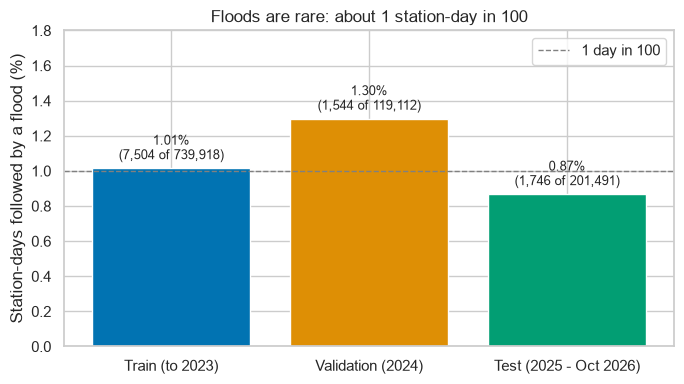

In [12]:
# One figure: how rare are flood days in each split?
fig, ax = plt.subplots(figsize=(7, 4))
rate = split_summary["flood_rate_%"]                       # flood rate (%) of train, validation and test
bars = ax.bar(rate.index, rate.values, color=sns.color_palette("colorblind")[:3])
# Write the rate and the counts on top of each bar
for bar, (n_flood, n_rows) in zip(bars, zip(split_summary["flood_days"], split_summary["rows"])):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
            f"{bar.get_height():.2f}%\n({n_flood:,} of {n_rows:,})", ha="center", va="bottom", fontsize=9)
# Dashed reference line at 1%
ax.axhline(1, color="grey", ls="--", lw=1, label="1 day in 100")
ax.set(ylabel="Station-days followed by a flood (%)", ylim=(0, 1.8),
       title="Floods are rare: about 1 station-day in 100")
ax.legend()
plt.tight_layout(); plt.show()

Figure 3 shows that floods are rare in all three splits, at roughly one station-day in 100. This has two consequences for the modelling. Firstly, accuracy is not a useful measure: a model that always predicts "no flood" would be about 99% accurate while never finding a flood, so we use precision (how many predicted floods were real), recall (how many real floods were found) and F1 instead. Secondly, the model has to be told that floods matter more than normal days, otherwise it will mostly predict "no flood".

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

## Clustering

When first approaching clustering the number of clusters from the elbow plot and the mean silhouette score for k = 2 to 10. On its own the mean silhouette isn't enough here: it is highest at k = 2, but that split turns out to be just coast versus river, which we already knew. So, following the third workshop, we added three more checks. The silhouette value of every station (violin plots), Ward hierarchical clustering to see whether a different method finds the same groups, and a stability test where k-means is refitted on random 80% samples of the stations.

We implement this to compare k-means (with k-means++ initialisation) and Ward hierarchical clustering for k = 2 to 8 clusters, using the elbow method, silhouette scores, agreement between the two methods, and stability under resampling.


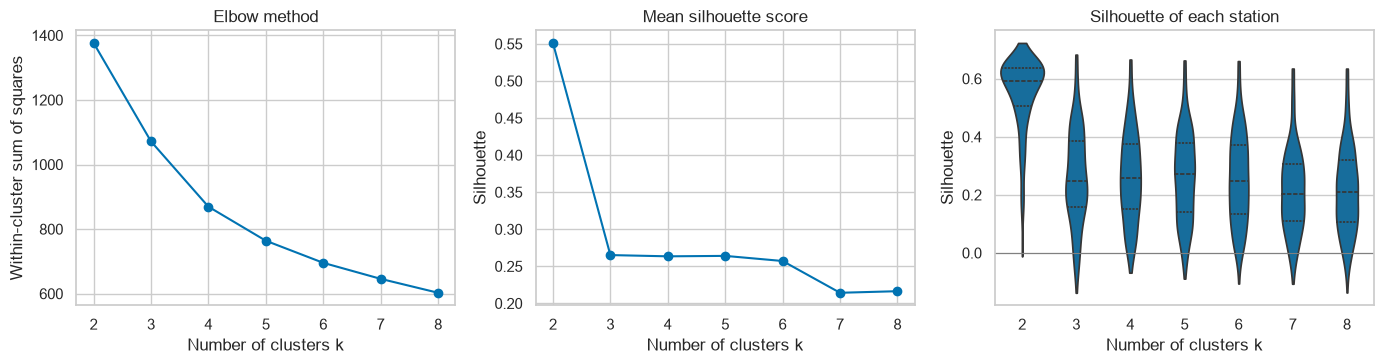

In [13]:
# ==============================================================================
# OLD APPROACH: elbow plot and mean silhouette only, k = 2 to 10
# Problem: the mean silhouette alone points to k = 2, which only splits coast from
# river. It also used X_scaled from the old features, which no longer exist.
# Kept for reference only. It is commented out and does not run.
# ==============================================================================
# Use k-means++ as from workshop we saw faster convergence and better clustering results than random initialisation.
#  We will try different values of K (number of clusters) to find the optimal number of clusters for our data.

# K_range = range(2, 11)
# inertias, silhouettes = [], []

# for k in K_range:
#     km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=0) # n_init = 10 to run the algorithm 10 times with different centroid seeds and take the best one (gives us the best result)
#     labels = km.fit_predict(X_scaled)
#     inertias.append(km.inertia_)
#     silhouettes.append(silhouette_score(X_scaled, labels))

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# ax1.plot(K_range, inertias, marker="o")
# ax1.set_title("Elbow Method (Inertia)")
# ax1.set_xlabel("Number of Clusters (K)")
# ax1.set_ylabel("Inertia (explained Variance)")

# ax2.plot(K_range, silhouettes, marker="o", color="orange")
# ax2.set_title("Silhouette Score")
# ax2.set_xlabel("Number of Clusters (K)")
# ax2.set_ylabel("Score")
# plt.show()


# ==============================================================================
# NEW APPROACH: elbow, mean silhouette and per-station silhouette violins, k = 2 to 8
# Adapted from Workshop 3: k-means++ (Ex 3), elbow plot (Ex 5), silhouette analysis (Ex 6)
# ==============================================================================
# Try every number of clusters from 2 to 8
K_range = range(2, 9)
km_labels, rows = {}, []      # km_labels: cluster of each station for every k; rows: scores for the table
for k in K_range:
    # k-means++ spreads out the starting centres; n_init=20 runs it 20 times and keeps the best run
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=0).fit(X)
    km_labels[k] = km.labels_
    # inertia = within-cluster sum of squares (for the elbow); silhouette = how well separated the clusters are
    rows.append({"k": k, "inertia": km.inertia_, "silhouette_kmeans": silhouette_score(X, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")    # one row per k

# Silhouette of every station for each k, to show how the scores are spread, not just the mean
sil_long = pd.concat([pd.DataFrame({"k": k, "silhouette": silhouette_samples(X, km_labels[k])})
                      for k in K_range])

# Three plots side by side (Figure 4)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
# Left: elbow plot
k_table["inertia"].plot(ax=axes[0], marker="o")
axes[0].set(title="Elbow method", ylabel="Within-cluster sum of squares")
# Middle: mean silhouette for each k
k_table["silhouette_kmeans"].plot(ax=axes[1], marker="o")
axes[1].set(title="Mean silhouette score", ylabel="Silhouette")
# Right: every station's silhouette for each k (below 0 = closer to another cluster than its own)
sns.violinplot(data=sil_long, x="k", y="silhouette", ax=axes[2], cut=0, inner="quartile")
axes[2].axhline(0, color="grey", lw=0.8)
axes[2].set(title="Silhouette of each station", ylabel="Silhouette")
for ax in axes:
    ax.set_xlabel("Number of clusters k")
plt.tight_layout(); plt.show()

**Observation:** Figure 4 shows the elbow curve, the mean silhouette score and the silhouette of every station for k = 2 to 8. The mean silhouette is by far the highest at k = 2 (0.55), but drops to about 0.26 for k = 3–6 and falls further for k = 7–8. The elbow curve bends at around k = 4. The violin plots show that at k = 2 almost every station is well placed (silhouette above 0), while from k = 3 onwards a small number of stations fall below 0, meaning they lie between clusters.


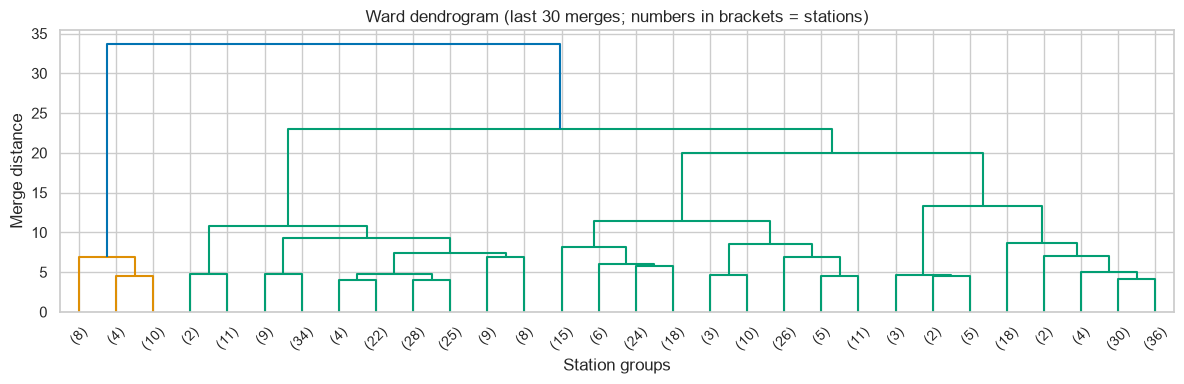

is_tidal         0   1
cluster (k=2)         
0              368   0
1                0  24


,inertia,silhouette_kmeans,silhouette_ward,ARI_kmeans_vs_ward,stability_kmeans
k,,,,,
2,1376.400,0.551,0.557,0.948,0.873
3,1071.384,0.265,0.209,0.449,0.873
4,869.296,0.263,0.232,0.690,0.909
5,763.908,0.264,0.227,0.623,0.849
6,695.485,0.257,0.215,0.653,0.774
7,645.889,0.214,0.231,0.438,0.610
8,602.781,0.216,0.187,0.402,0.642


In [14]:
# Adapted from Workshop 3 (Ex 8-9): Ward hierarchical clustering and dendrogram
# Ward linkage: repeatedly merge the two groups whose merge adds the least within-group variance
Z = hierarchy.linkage(X, method="ward")
# Dendrogram of the last 30 merges (Figure 5); a long vertical line = a big jump = a natural split
fig, ax = plt.subplots(figsize=(12, 4))
hierarchy.dendrogram(Z, truncate_mode="lastp", p=30, ax=ax)
ax.set(title="Ward dendrogram (last 30 merges; numbers in brackets = stations)",
       xlabel="Station groups", ylabel="Merge distance")
plt.tight_layout(); plt.show()

# For each k: Ward silhouette, how much KMeans and Ward agree, and how stable KMeans is
# when refitted on random 80% subsamples (adjusted Rand index (ARI): 1 = identical clusters, 0 = chance)
rng = np.random.default_rng(0)                    # fixed seed so the random samples are the same every run
for k in K_range:
    ward = hierarchy.fcluster(Z, t=k, criterion="maxclust")                     # cut the Ward tree into k groups
    k_table.loc[k, "silhouette_ward"] = silhouette_score(X, ward)               # how well separated Ward's groups are
    k_table.loc[k, "ARI_kmeans_vs_ward"] = adjusted_rand_score(km_labels[k], ward)   # do the two methods agree?
    aris = []
    for b in range(20):                                                         # 20 random 80% samples
        idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)        # pick 80% of the stations
        sub = KMeans(n_clusters=k, n_init=10, random_state=b).fit_predict(X[idx])   # re-cluster only those
        aris.append(adjusted_rand_score(km_labels[k][idx], sub))               # compare with the full fit
    k_table.loc[k, "stability_kmeans"] = np.mean(aris)                          # average agreement = stability

# Check what the k = 2 split is: coastal vs river?
print(pd.crosstab(km_labels[2], station["is_tidal"], rownames=["cluster (k=2)"], colnames=["is_tidal"]))
# All the scores for every k in one table
k_table.round(3)

**Observation:** From the cross-tabulation we can see that using k=2 gives a perfect separation of the 24 coastal stations and 368 river stations even though the coastal indicator variable wasn’t used. This demonstrates that we are capturing real differences in behaviour between the stations. Unfortunately, whilst the mean silhouette value is quite consistent for k values of 3 to 6 (all around 0.26), there is no clear best choice of k. 

Looking at the stability of the clusters by refitting the k-means algorithm on 80% random subsets of stations, k=4 had the most stable clusters (ARI=0.91). We can also see from the Ward dendrogram (Figure 5) that after splitting up the coastal stations at the furthest merge distance, the river stations split up into 3 groups at a point where the merge distances drop significantly.

We therefore choose **k-means with k = 4**: one coastal group and three river groups. The moderate silhouette score (0.26) indicates that the river clusters overlap to some extent, which is expected because river behaviour varies gradually rather than falling into perfectly distinct types.


,n_stations,n_coastal,spread_m,flashiness,skewness,seasonality,log_daily_swing
cluster,,,,,,,
0,116,0,0.96,0.27,1.36,0.51,-1.21
1,147,0,0.62,0.40,1.46,0.44,-1.03
2,105,0,0.38,0.24,2.13,0.52,-1.26
3,24,24,1.00,0.53,0.29,0.24,0.41


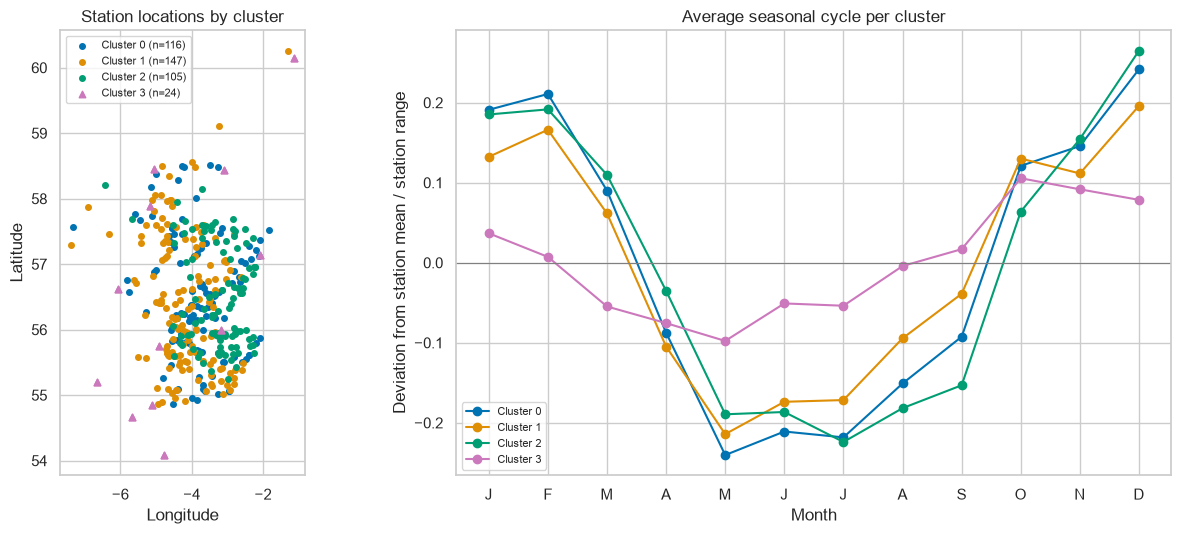

In [15]:
K = 4              # chosen above: elbow, highest stability, best agreement with Ward
METHOD = "kmeans"  # switch to "ward" to use the hierarchical clusters instead
# Cluster label of every station (Ward labels start at 1, so subtract 1 to match k-means)
labels = km_labels[K] if METHOD == "kmeans" else hierarchy.fcluster(Z, t=K, criterion="maxclust") - 1
station["cluster"] = labels

# Table: number of stations, number of coastal ones and the median of each feature per cluster
summary = station.groupby("cluster").agg(
    n_stations=("cluster", "size"), n_coastal=("is_tidal", "sum"),
    **{c: (c, "median") for c in feature_cols})
# Show the spread back in metres (undo the log) so it is easier to read
summary.insert(2, "spread_m", np.exp(summary.pop("log_spread")))
display(summary.round(2))

# Distinct colours for each cluster (purple for the coastal cluster, so it isn't confused with orange)
palette = [sns.color_palette("colorblind")[i] for i in (0, 1, 2, 4)]
markers = ["o", "o", "o", "^"]  # triangles for the coastal gauges

# Two panels (Figure 6): map on the left, seasonal cycle on the right
fig, (ax_map, ax_season) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
# Left: every station at its longitude/latitude, coloured by cluster
for c in range(K):
    s = station[station["cluster"] == c]
    ax_map.scatter(s["Longitude"], s["Latitude"], s=22 if c == 3 else 16, marker=markers[c],
                   color=palette[c], label=f"Cluster {c} (n={len(s)})")
ax_map.set_aspect(1 / np.cos(np.deg2rad(57)))  # correct the map's aspect ratio for Scotland's latitude
ax_map.set(xlabel="Longitude", ylabel="Latitude", title="Station locations by cluster")
ax_map.legend(fontsize=8)

# Right: seasonal cycle as a fraction of each station's own range, so stations are comparable
season = row_norm.loc[station.index].div(spread.loc[station.index], axis=0)
for c in range(K):
    # Average monthly pattern of all stations in cluster c
    ax_season.plot(range(1, 13), season[station["cluster"] == c].mean().values,
                   marker="o", color=palette[c], label=f"Cluster {c}")
ax_season.axhline(0, color="grey", lw=0.8)       # 0 = the station's yearly average
ax_season.set_xticks(range(1, 13), ["J","F","M","A","M","J","J","A","S","O","N","D"])
ax_season.set(xlabel="Month", ylabel="Deviation from station mean / station range",
              title="Average seasonal cycle per cluster")
ax_season.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation:** The table above gives the median value of each feature per cluster, and Figure 6 shows the station locations (left) and the average seasonal cycle of each cluster (right).

Cluster 3 contains exactly the 24 coastal series, shown as triangles around the coastline. The three river clusters differ mainly in the size of their range, how quickly they respond and how skewed their levels are: cluster 1 is the most flashy (median flashiness 0.40), cluster 2 has the smallest range (about 0.4 m) and the slowest response, and cluster 0 has the largest range (about 1 m).

The map shows a west–east pattern: cluster 1 stations are concentrated in the west, cluster 2 stations in the east, and cluster 0 stations are spread across the country. The seasonal plot shows that all river clusters are high in winter and low from May to July, but they recover at different speeds: cluster 1 rises earliest (from August), while cluster 2 stays low the longest (until September). The coastal cluster has a much weaker seasonal cycle. These clusters are interpreted in detail in the next section.


## Flood Classification

To predict whether a station floods tomorrow we start with a simple baseline: a logistic regression on the 21 seven-day features (Workshop 6). Every model is scored with the same evaluation function on the same validation and test data, so the final model can be compared directly with this baseline.

### Evaluation function

The function below is used to score every model. It takes any fitted classifier and returns precision, recall, F1 and the confusion matrix for the flood class, and evaluate_on_splits does this for the validation and test sets and plots the confusion matrices. The same function and the same data splits should be used for the other model, so both models are scored in exactly the same way (for example evaluate_on_splits(model, splits, "Model name")). The threshold argument sets how high the predicted flood probability has to be before we predict a flood, so it can be chosen using the validation set.

In [16]:
# Metrics and confusion matrices adapted from Workshop 6 (Ex 4-6)
def evaluate_classifier(model, X, y, threshold=0.5):
    """
    Score a fitted binary classifier on one data set. 
    Every model is scored with this function so the results can be compared fairly.
    The flood class (1) is the positive class and accuracy is not reported because a model that never predicts a flood would already be about 99% accurate.

    Parameters
    ----------
    model : fitted classifier with predict_proba (or predict if it has none).
    X, y : features and true flood labels (0/1).
    threshold : predicted flood probability above which we predict a flood.

    Returns
    -------
    dict with precision, recall, f1, the 2x2 confusion matrix
    ([[TN, FP], [FN, TP]]) and the number of true flood days.
    """
    # Turn the model's output into 0/1 predictions
    if hasattr(model, "predict_proba"):
        # Probability of a flood for every row; predict a flood when it reaches the threshold
        pred = (model.predict_proba(X)[:, 1] >= threshold).astype(int)
    else:
        # Models without probabilities give 0/1 directly
        pred = model.predict(X)
    # Scores for the flood class (zero_division=0 avoids an error if the model never predicts a flood)
    return {
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "confusion_matrix": confusion_matrix(y, pred, labels=[0, 1]),
        "n_floods": int(np.sum(y)),
    }


def evaluate_on_splits(model, splits, model_name="Model", threshold=0.5, plot=True):
    """
    Run evaluate_classifier on several data sets and show the results together.

    Parameters
    ----------
    model : fitted classifier.
    splits : dict of name -> (X, y), e.g. {"Validation": (X_val, y_val), "Test": (X_test, y_test)}.
    model_name : label used in the table and plot titles.
    threshold : probability threshold passed to evaluate_classifier.
    plot : if True, draw a confusion matrix for each data set.

    Returns
    -------
    DataFrame with one row per data set (precision, recall, f1, TN, FP, FN, TP).
    """
    rows, matrices = [], {}          # rows for the results table, confusion matrices for the plot
    for name, (X, y) in splits.items():
        # Score the model on this data set
        res = evaluate_classifier(model, X, y, threshold)
        # Unpack the confusion matrix: true negatives, false positives, false negatives, true positives
        (tn, fp), (fn, tp) = res["confusion_matrix"]
        matrices[name] = res["confusion_matrix"]
        rows.append({"model": model_name, "data": name, "precision": res["precision"],
                     "recall": res["recall"], "f1": res["f1"], "TN": tn, "FP": fp, "FN": fn, "TP": tp})

    # One confusion matrix heatmap per data set, side by side
    if plot:
        fig, axes = plt.subplots(1, len(matrices), figsize=(5 * len(matrices), 4))
        for ax, (name, cm) in zip(np.atleast_1d(axes), matrices.items()):
            sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                        xticklabels=["No flood", "Flood"], yticklabels=["No flood", "Flood"])
            ax.tick_params(axis="y", labelrotation=0)
            ax.set(xlabel="Predicted", ylabel="Actual", title=f"{model_name}: {name}")
        plt.tight_layout(); plt.show()
    # Results table, one row per data set
    return pd.DataFrame(rows).set_index(["model", "data"])

### Baseline: logistic regression

We fit a logistic regression on the 21 scaled features, as in Workshop 6. It is simple and
fast, and each coefficient can be interpreted. Because floods are so rare we use balanced
class weights, which make a missed flood count more than a false alarm during fitting. We
also fit the model without weights to show why the weights matter.

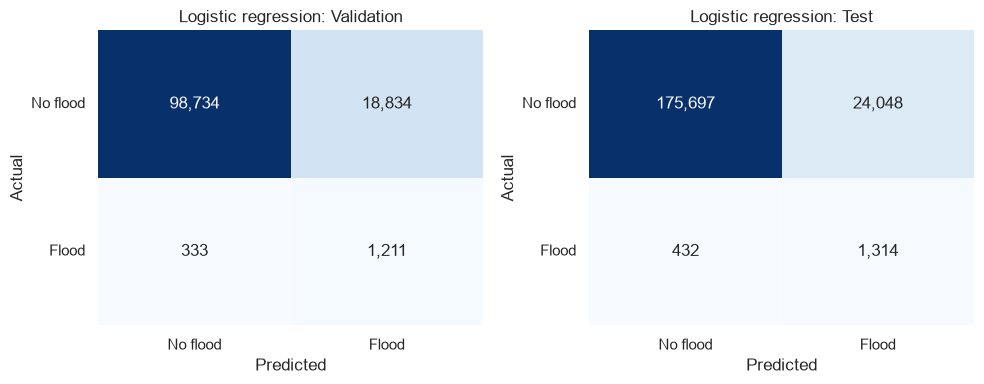

precision  recall     f1      TN  \
model                            data                                           
Logistic regression              Validation      0.060   0.784  0.112   98734   
                                 Test            0.052   0.753  0.097  175697   
Logistic regression (no weights) Validation      0.497   0.050  0.091  117490   
                                 Test            0.410   0.056  0.099  199604   

                                                FP    FN    TP  
model                            data                           
Logistic regression              Validation  18834   333  1211  
                                 Test        24048   432  1314  
Logistic regression (no weights) Validation     78  1467    77  
                                 Test          141  1648    98

Max_lag0    1.30
Avg_lag2   -0.54
Min_lag0    0.37
Max_lag2    0.34
Avg_lag0   -0.34
dtype: float64

In [17]:
# Adapted from Workshop 6: logistic regression with class weights for imbalanced data
# Baseline: logistic regression on the 21 scaled features.
# class_weight="balanced" gives floods more weight, otherwise with only 1% floods the model rarely predicts one
baseline = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=0)
baseline.fit(X_train, y_train)                 # learn the weights from the training years only

# The data sets to score on: validation (2024) and test (2025 - Oct 2026)
splits = {"Validation": (X_val, y_val), "Test": (X_test, y_test)}
# Scores and confusion matrices (Figure 7)
baseline_results = evaluate_on_splits(baseline, splits, model_name="Logistic regression")

# For comparison: the same model without the class weights
plain = LogisticRegression(max_iter=1000, random_state=0).fit(X_train, y_train)
plain_results = evaluate_on_splits(plain, splits, model_name="Logistic regression (no weights)", plot=False)
# Both models' scores in one table
display(pd.concat([baseline_results, plain_results]).round(3))

# Largest coefficients (the features are all on the same scale, so they can be compared)
coefs = pd.Series(baseline.coef_[0], index=feature_cols_clf)
# Sort by size, ignoring the sign, and show the top 5
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5).round(2)

**Observation:** Figure 7 shows the confusion matrices for the validation and test data.

The baseline finds most floods but raises many false alarms. On the validation data it finds 78% of floods (1,211 of 1,544) with a precision of only 0.06 (F1 = 0.11), and on the test data it finds 75% (1,314 of 1,746) with a precision of 0.05 (F1 = 0.10). In practice this means that only around 1 in 17 flood warnings on validation (1 in 19 on test) would be a real flood. The results on the two sets are similar, so the model is not simply fitting the training years, but the low precision shows that a linear model of the last seven days is not enough to separate a coming flood from a day that is simply high.

Without class weights the model almost never predicts a flood: precision is higher (0.50 on validation) but recall drops to about 5%, so it misses nearly every flood. The largest coefficient by far is today's maximum level (Max_lag0), which means the model mostly predicts that a station already near flood level will still be high tomorrow. The balanced baseline is the one we compare the other model against.

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

## Clustering

We grouped the 392 monitoring series into four clusters based on how their water levels behave, rather than on their absolute level or location:

| Cluster | Stations | Description |
|---|---|---|
| 3: Coastal gauges | 24 | Sea-level gauges. Large movements within each day (tides), roughly symmetric levels and only a weak seasonal cycle, highest in autumn. |
| 1: Flashy rivers | 147 | Rivers that rise and fall quickly from day to day and recover earliest from summer low levels. Mostly located in the west of Scotland. |
| 0: Large seasonal rivers | 116 | Rivers with the largest typical range (about 1 m), a moderate response and a strong winter-high / summer-low cycle. Spread across Scotland. |
| 2: Slow rivers with rare peaks | 105 | Rivers with the smallest typical range (about 0.4 m) and the slowest response, but the most skewed levels: long quiet periods broken by occasional sharp rises. Their summer low lasts longest. Mostly located in the east. |

There are two reasons why it appears that these groupings are meaningful. Firstly, there is a distinct grouping within the coastal series despite the coastal flag not being considered. Secondly, there is a clear west to east trend with the river clusters on the map. This makes sense as the western catchments will be wetter and steeper meaning they respond quicker to rainfall than the drier and flatter eastern catchments.

**Implications for river management.** Flashy western rivers (cluster 1) can rise within a day, so flood warnings there need short lead times and frequent monitoring. Slow eastern rivers (cluster 2) are usually quiet but occasionally produce sharp peaks, so long periods of normal readings should not be taken as a sign of low flood risk. Coastal gauges (cluster 3) are driven by tides and storm surges rather than rainfall and should be monitored separately from rivers.

**Limitations.** The silhouette score for the river clusters is moderate (about 0.26), so the boundaries between river types are gradual rather than sharp, and stations near a boundary could reasonably belong to either neighbouring cluster. Stations also have different recording periods, and the features use only water levels; adding rainfall, catchment size or land use would likely give clearer groups.


### Summary of the data cleaning and clustering

**What we did.** We started from four files of daily river levels for 392 monitoring series (October 2014 – October 2026). We checked that the three level files match, combined them into one table with one row per series per day, cleaned out impossible readings, and then grouped the stations by how their water levels behave.

**Why we did it this way.**
- *Coastal series:* 12 series were labelled "tidal", but each has a partner at the same site that moves almost identically (correlation 0.97–0.999). Both measure the sea rather than a river, so we flagged all 24 as coastal.
- *Cleaning:* each gauge measures from its own zero point, so one rule for all of Scotland does not work. For example, Lochy at Lochaber normally reads about 29.7 m and a ±20 m limit would have deleted almost all of its data. Instead, we compared every reading with its own station's normal range and removed only values far outside it (about 200 per series, under 0.02% of the data). This removed the error codes but kept genuine flood peaks.
- *Features:* we described each station by five features that do not depend on the gauge's zero point: how much the level varies, how quickly it changes from day to day, whether it has rare sharp peaks, how seasonal it is, and how much it moves within a day. We did not use location, the coastal flag or the amount of data, so that the clusters reflect river behaviour only.
- *Choosing the number of clusters:* the silhouette score alone could not choose between 3 and 6 clusters. We therefore also compared k-means with Ward hierarchical clustering and checked how stable the clusters were on random subsets of stations. Four clusters gave the most stable result and the closest agreement between the two methods.

**What we found.** Four groups: coastal gauges (24), flashy rivers mostly in the west (147), large seasonal rivers across Scotland (116), and slow rivers with rare sharp peaks mostly in the east (105). The coastal series formed their own group and the river groups showed a west–east pattern, even though neither the coastal flag nor location was used. This gives us confidence that the groups are real.

**How this feeds into the classification.** The cleaned data are used for the flood classification: predicting whether a station floods on the next day from the previous seven days. The coastal series are left out and the data are split by date rather than at random. The cluster labels can also be used to check whether the flood model works better for some types of river than others.


# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

1. MATH11205 Machine Learning in Python, Workshop 1: Exploratory Data Analysis and Feature Engineering, solutions notebook. University of Edinburgh, 2026. Approach used for data cleaning, log transforms and standardising features.
2. MATH11205 Machine Learning in Python, Workshop 3: Clustering, solutions notebook. University of Edinburgh, 2026. Code adapted for k-means++ (Ex 3), the elbow plot (Ex 5), silhouette analysis (Ex 6), standardisation (Ex 7) and hierarchical clustering with dendrograms (Ex 8–9).
3. MATH11205 Machine Learning in Python, Workshop 6: Logistic Regression, solutions notebook. University of Edinburgh, 2026. Code adapted for logistic regression, classification metrics and confusion matrices (Ex 4–6) and class weights for imbalanced data.
4. MATH11205 Machine Learning in Python, Workshop 8: Trees and Ensembles, solutions notebook. University of Edinburgh, 2026.
5. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
6. 1993 Perth flood. Wikipedia. https://en.wikipedia.org/wiki/1993_Perth_flood (accessed November 2026).
7. Scottish Environment Protection Agency (SEPA). Water levels, station 234235. https://waterlevels.sepa.org.uk/Station/234235 (accessed November 2026).
8. Scottish Government. Scotland's Marine Assessment, map 423. https://marine.gov.scot/sma/maps/423 (accessed November 2026).


In [19]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files\
[NbConvertApp] Making directory .\project_files
[NbConvertApp] Writing 173215 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] CRITICAL | x failed: xelatex notebook.tex -quiet
b''
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\thoma\AppData\Roaming\Python\Python312\Scripts\jupyter-nbconvert.EXE\__main__.py", line 5, in <module>
  File "C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\jupyter_core\application.py", line 284, in launch_instance
    super().launch_instance(argv=argv, **kwargs)
  File "C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "C:\Users\thoma\AppD